# 状態変数フィルタ

ここまでの 2 次のフィルタ(LPF、HPF、BPF、ノッチ)を、**1 つの回路からまとめて取り出せる**フィルタです。$f_c$ と Q を別々に調整しやすいので、シンセサイザーや測定器でよく使われます。**Mimic の 2 次のフィルタも、この形で計算しています。**

この回では、4 種類の出力を並べて比べ、それらのあいだの関係(足すと入力に戻る)を確かめます。

## 回路(ブロック図)

![状態変数フィルタのブロック図](05_svf/circuit.svg)

足し算(Σ)と、2 つの**積分器**($\omega_0 / s$、$\omega_0 = 2\pi f_c$)をつないだ形です。積分器の出力(BP、LP)を足し算に戻しています。実際の回路では、足し算と積分器をそれぞれオペアンプ 1 個で作り、3〜4 個のオペアンプで組みます(KHN 型、Tow-Thomas 型など)。

積分器は「入力を時間で積み上げる」回路で、周波数が高いほど出力が小さく、位相が 90° 遅れます。積分器の回は 4 章で扱います。

## 原理

ブロック図から、3 つの出力のあいだに次の関係があります。

$$\mathrm{HP} = V_\mathrm{in} - \frac{\mathrm{BP}}{Q} - \mathrm{LP}, \qquad \mathrm{BP} = \frac{\omega_0}{s}\,\mathrm{HP}, \qquad \mathrm{LP} = \frac{\omega_0}{s}\,\mathrm{BP}$$

これを解くと(導出は省きます)、それぞれが 2 次の HPF、BPF、LPF になります。$D = 1 - (f/f_c)^2 + j\,\dfrac{f/f_c}{Q}$ として、

| 出力 | 伝達関数 | Mimic の設定 |
|---|---|---|
| LP | $1 / D$ | `biquad_lpf(fc, q)` |
| HP | $-(f/f_c)^2 / D$ | `biquad_hpf(fc, q)` |
| BP / Q | $j\,\dfrac{f/f_c}{Q} \Big/ D$($f_c$ で 1) | `biquad_bpf(fc, q)` |
| HP + LP | $\left(1 - (f/f_c)^2\right) / D$ | `biquad_notch(fc, q)` |

1 つ目の式を並べかえると、

$$\mathrm{HP} + \frac{\mathrm{BP}}{Q} + \mathrm{LP} = V_\mathrm{in}$$

つまり、**HPF、BPF、LPF の出力を足すと入力に戻ります**。ノッチは BPF を除いた残り(HP + LP = 入力 − BP/Q)です。

$f_c$ は 2 つの積分器の速さ($\omega_0$)だけで、Q は戻す量($1/Q$)だけで決まり、別々に調整できます。

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.biquad_lpf(fc, q)` など | `mimic.setFilterBiquadLPF(fc, Q)` など | 積分器の時定数 $RC = \dfrac{1}{2\pi f_c}$、戻す量 $1/Q$ |

Mimic は 1 台で 1 つの出力しか出せないので、出力の種類は設定で選びます。$f_c$ と Q の意味は、どの種類でも同じです。

## 準備:測定器につなぐ

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, Monitor, fit_sine, match_phase, plot_waveforms

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.0, mimic=20261123)

In [2]:
import time

FC, Q = 100, 1  # the same fc and Q for every output
KINDS = {"lpf": lab.mimic.biquad_lpf, "hpf": lab.mimic.biquad_hpf,
         "bpf": lab.mimic.biquad_bpf, "notch": lab.mimic.biquad_notch}

def bode_axes(title):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
    ax1.set_title(title)
    ax1.set_ylabel("Gain [dB]")
    ax2.set_ylabel("Phase [deg]")
    ax2.set_xlabel("Frequency [Hz]")
    for ax in (ax1, ax2):
        ax.grid(True, which="both", alpha=0.4)
    return fig, ax1, ax2


def second_order(f, fc, q, kind):
    # Response of the module: lpf 1/D, hpf s^2/D, bpf (s/Q)/D, notch (s^2 + 1)/D
    s = 1j * f / fc
    d = s * s + s / q + 1
    return {"lpf": 1, "hpf": s * s, "bpf": s / q, "notch": s * s + 1}[kind] / d

## 実験 1:4 種類の出力を並べる

30 Hz の方形波を入れて、出力の種類を順に切り替えて取り込みます。取り込みは信号発生器の位相 0 から始まるので、別々に取り込んでも時刻がそろいます。

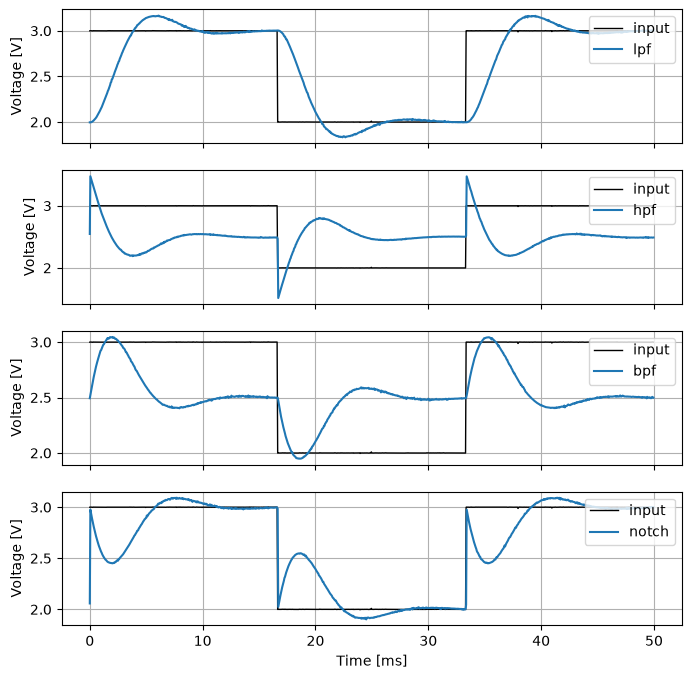

In [3]:
lab.fg.square(30, 0.5)
out = {}
for kind, set_mode in KINDS.items():
    set_mode(FC, Q)
    time.sleep(0.3)  # wait for the filter to settle
    t, ch1, ch2 = lab.scope.capture(1000)  # 50 ms
    out[kind] = ch2

fig, axes = plt.subplots(4, 1, figsize=(8, 8), sharex=True)
for ax, (kind, v) in zip(axes, out.items()):
    ax.plot(t * 1e3, ch1, "k", lw=1, label="input")
    ax.plot(t * 1e3, v, label=kind)
    ax.set_ylabel("Voltage [V]")
    ax.grid(True)
    ax.legend(loc="upper right")
axes[-1].set_xlabel("Time [ms]")
plt.show()

## 実験 2:足すと入力に戻る

Mimic の出力は Vref(2.5 V)からのずれが信号です。Vref を引いてから HPF、BPF、LPF の出力を足し、Vref を戻して入力と比べます。ノッチの出力が HPF + LPF になっていることも確かめます。

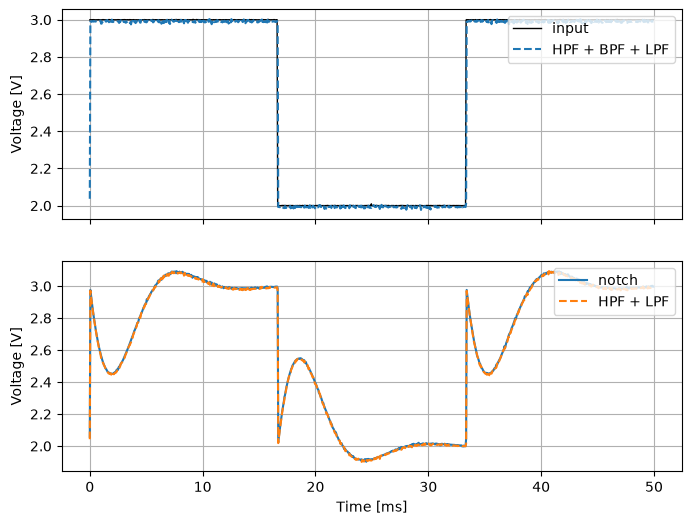

input - (HPF + BPF + LPF): rms 54.2 mV
notch - (HPF + LPF)      : rms 6.6 mV


In [4]:
VREF = 2.5
total = (out["hpf"] - VREF) + (out["bpf"] - VREF) + (out["lpf"] - VREF) + VREF
hp_lp = (out["hpf"] - VREF) + (out["lpf"] - VREF) + VREF

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax1.plot(t * 1e3, ch1, "k", lw=1, label="input")
ax1.plot(t * 1e3, total, "--", label="HPF + BPF + LPF")
ax2.plot(t * 1e3, out["notch"], label="notch")
ax2.plot(t * 1e3, hp_lp, "--", label="HPF + LPF")
for ax in (ax1, ax2):
    ax.set_ylabel("Voltage [V]")
    ax.grid(True)
    ax.legend(loc="upper right")
ax2.set_xlabel("Time [ms]")
plt.show()
print(f"input - (HPF + BPF + LPF): rms {np.sqrt(np.mean((ch1 - total) ** 2)) * 1e3:.1f} mV")
print(f"notch - (HPF + LPF)      : rms {np.sqrt(np.mean((out['notch'] - hp_lp) ** 2)) * 1e3:.1f} mV")

切り替わりの直後に少し差が出るのは、Mimic の遅れと、出力の範囲(電源の内側)で頭打ちになった部分があるためです。

## 実験 3:4 種類のボード線図

同じ $f_c$ と Q で、4 種類の周波数特性を重ねます。

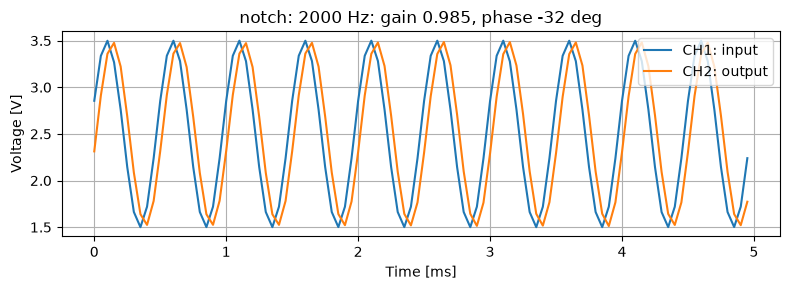

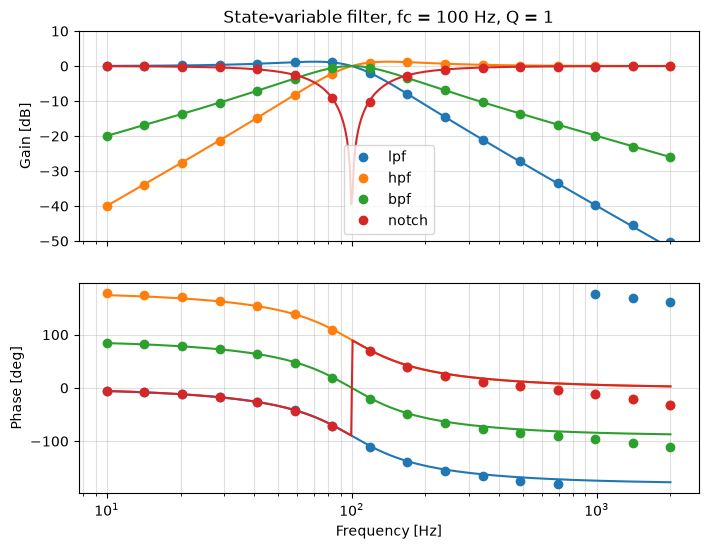

In [5]:
freqs = np.logspace(1, np.log10(2000), 16)   # 10 Hz - 2 kHz
f_th = np.logspace(1, np.log10(2000), 400)
fig, ax1, ax2 = bode_axes(f"State-variable filter, fc = {FC} Hz, Q = {Q}")
rs = {}
mon = Monitor()  # one plot updated while measuring
for i, (kind, set_mode) in enumerate(KINDS.items()):
    set_mode(FC, Q)
    r = rs[kind] = lab.frequency_response(freqs, monitor=mon, label=f"{kind}: ")
    h = second_order(f_th, FC, Q, kind)
    ax1.semilogx(f_th, 20 * np.log10(np.maximum(abs(h), 1e-4)), "-", color=f"C{i}")
    ax2.semilogx(f_th, np.degrees(np.angle(h)), "-", color=f"C{i}")
    ax1.semilogx(r.freq, r.gain_db, "o", color=f"C{i}", label=kind)
    ax2.semilogx(r.freq, (r.phase + 180) % 360 - 180, "o", color=f"C{i}")
ax1.set_ylim(-50, 10)
ax1.legend()
mon.close()
plt.show()

各周波数で取り込んだ波形です(クリックで開きます)。


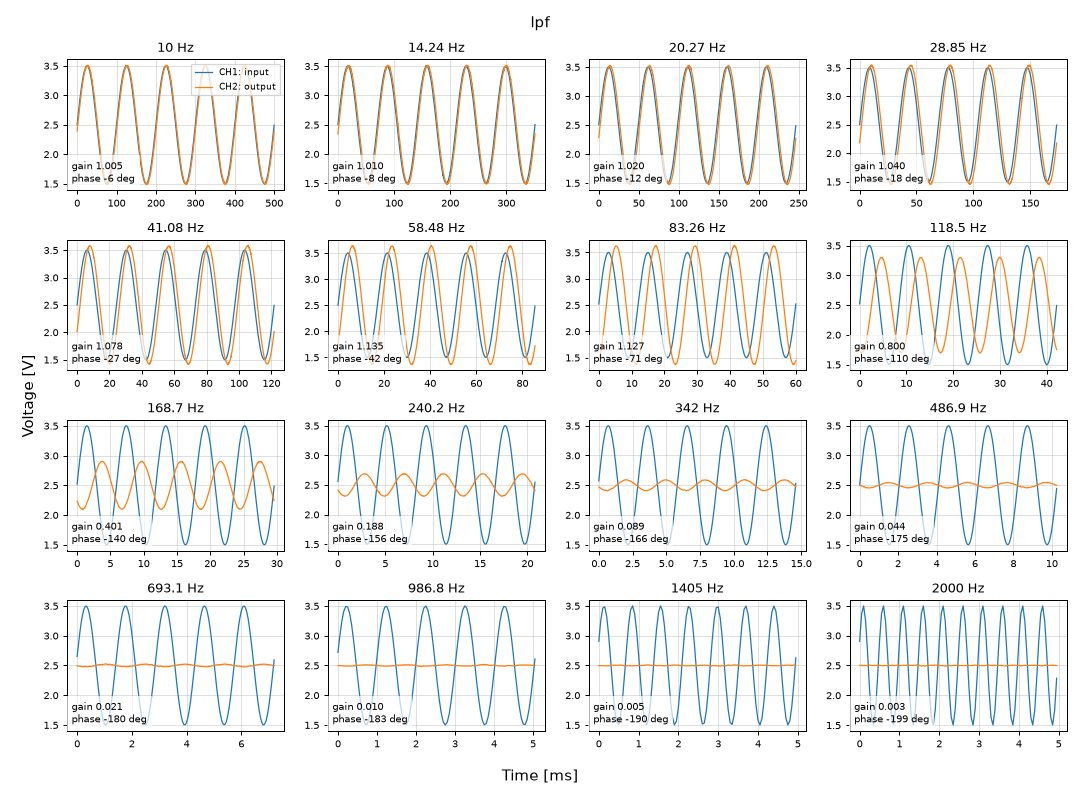


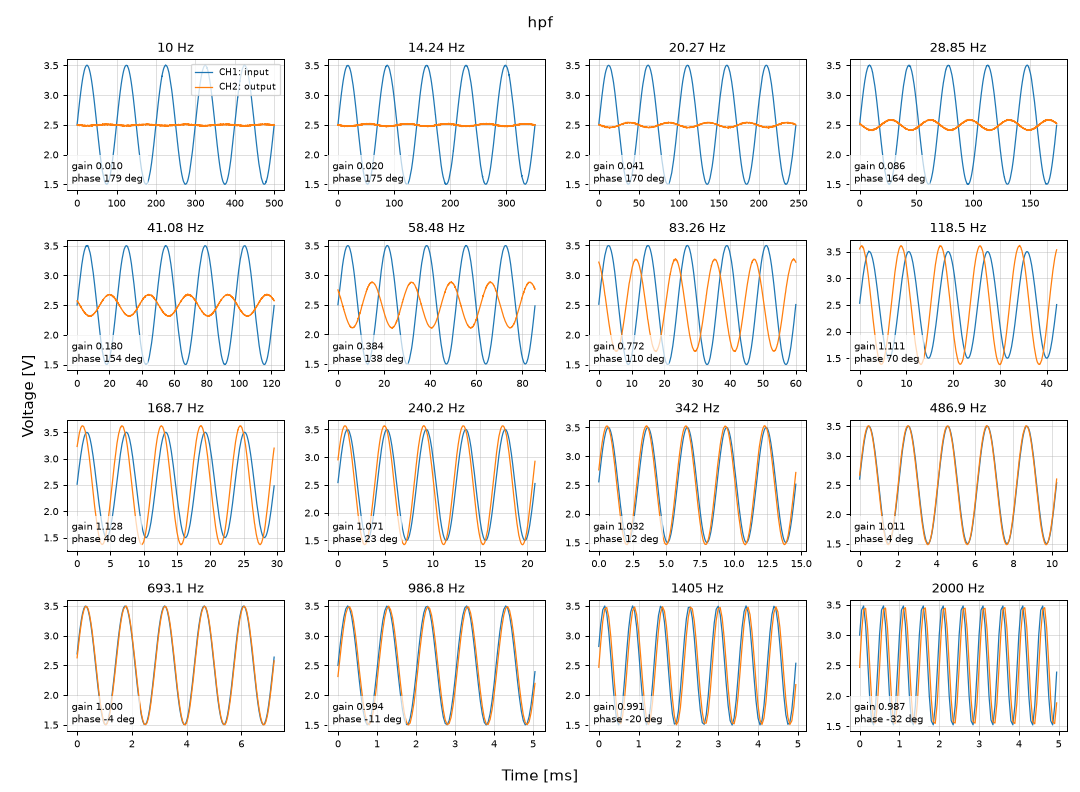


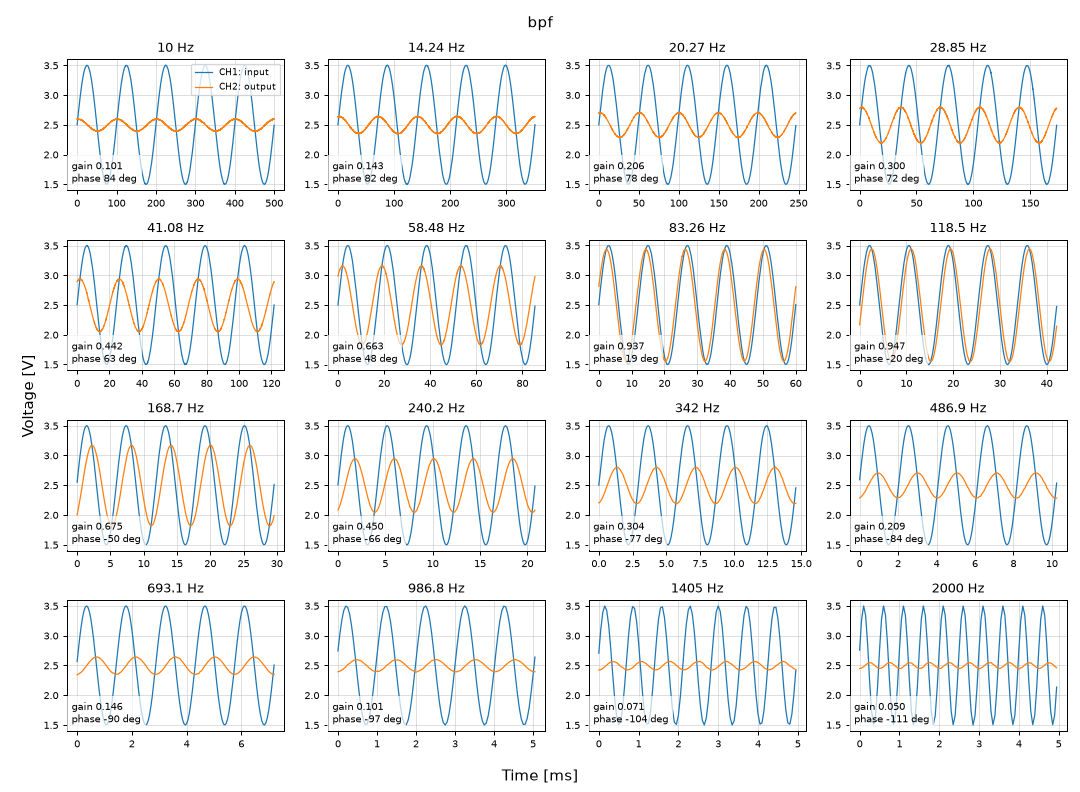


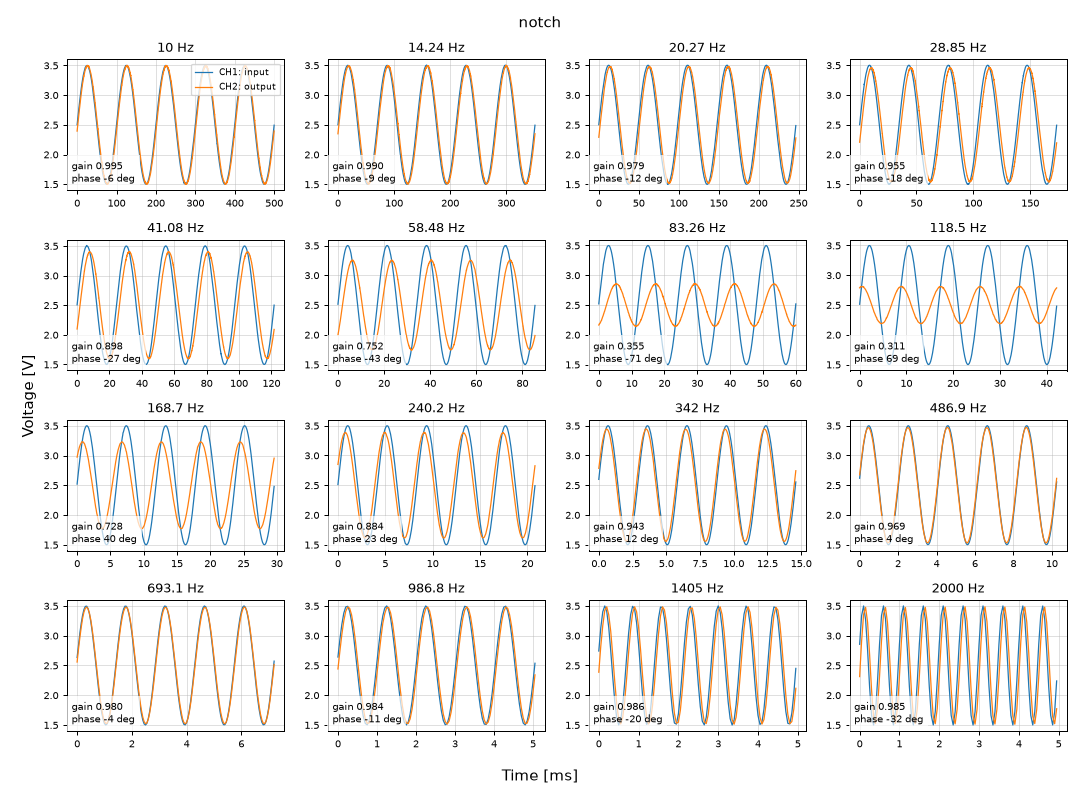

In [6]:
for key, r in rs.items():
    plot_waveforms(r, title=key, collapsed=True)

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 出力の種類と Q を変えて方形波を入れる
<details><summary>ヒント</summary>

`KIND` を `"lpf"` → `"bpf"` → `"hpf"` → `"notch"` と変え、それぞれ `Q_TRY` を 0.5 と 5 で試してみましょう。Q = 5 では、BPF の出力が $f_c$ でゆれ続け、LPF と HPF にも大きな振動が出ます。ノッチは、切り替わりの直後に $f_c$ の振動が抜けた形になります。

</details>

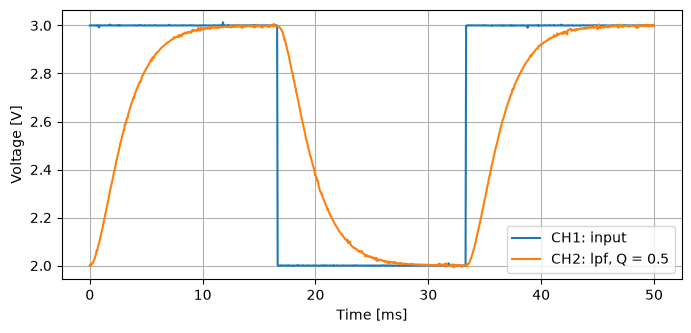

In [7]:
KIND = "lpf"   # "lpf", "hpf", "bpf" or "notch"
Q_TRY = 0.5

KINDS[KIND](FC, Q_TRY)
lab.fg.square(30, 0.5)
time.sleep(0.3)
t, ch1, ch2 = lab.scope.capture(1000)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: {KIND}, Q = {Q_TRY}")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 2. $f_c$ の正弦波で、出力の振幅と位相を比べる

$f_c$(100 Hz)の正弦波を入れて、出力の種類を変えます。表から予想してから確かめます。
<details><summary>ヒント</summary>

`KIND` を `"lpf"` → `"hpf"` → `"bpf"` → `"notch"` と変えてみましょう。Q = 1 の $f_c$ では、LPF が振幅 1・位相 −90°、HPF が振幅 1・位相 +90°、BPF が振幅 1・位相 0°、ノッチが振幅 0 です。LPF と HPF はちょうど逆向きなので、足すと 0 になり、ノッチ(HP + LP)が 0 になる理由がわかります。

</details>

lpf: gain 1.001, phase -91.1 deg


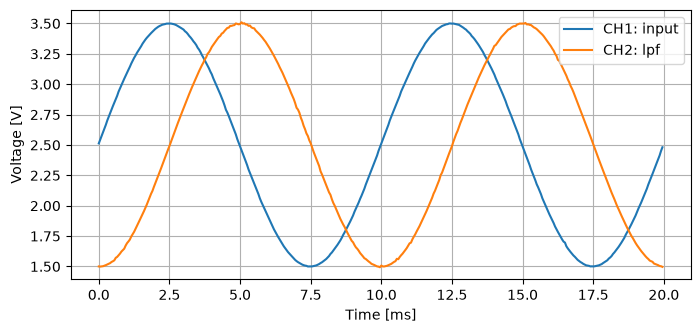

In [8]:
KIND = "lpf"   # "lpf", "hpf", "bpf" or "notch"

KINDS[KIND](FC, Q)
lab.fg.sine(FC, 1.0)
time.sleep(0.3)
t, ch1, ch2 = lab.scope.capture(400)
a1, p1, _ = fit_sine(t, ch1, FC)
a2, p2, _ = fit_sine(t, ch2, FC)
print(f"{KIND}: gain {a2 / a1:.3f}, phase {(p2 - p1 + 180) % 360 - 180:.1f} deg")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: {KIND}")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

## まとめ

- 状態変数フィルタは、足し算と 2 つの積分器で作る。HP、BP、LP の出力を同時に取り出せる。
- HPF + BPF + LPF = 入力、ノッチ = HPF + LPF。
- $f_c$ は積分器の速さで、Q は戻す量で、別々に決まる。Mimic の 2 次のフィルタ(`biquad_…`)は、この計算をデジタルで行っている。

最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [9]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()